# Take-Home Share: Net Pay Against What You Cost

Two numbers describe the same job. The one an employer budgets is the
*Arbeitgeberbrutto*: the gross salary plus the employer's half of the social
insurance. The one that matters to the employee is what lands on the card
after contributions and tax. This notebook plots the second as a percentage of
the first, across the whole salary range.

The answer is not a straight line and not even a monotone one. It falls from
about 61% at the bottom of the range to a floor just under 50% at the pension
ceiling, and then *climbs back* — because above the ceilings a raise carries no
more contributions, only the tariff, and the 42% bracket is cheaper than
42% plus 21.75% employee plus 21.15% employer.

Runs on the pure tax functions in
[`src/model/german_tax.py`](../src/model/german_tax.py) — the enacted 2026
parameters, the statutory euro-rounding included — not on the forecast engine:
this is one calendar year, not a projection.

**The person being modelled**

- single, no children, assessed alone, Steuerklasse I; no church tax
- statutory health and care insurance at the 2026 average Zusatzbeitrag of
  2.9%, with the childless surcharge (so, at least 23 years old)
- no deductions beyond the statutory lump sums — no Werbungskosten above the
  1,230 € Arbeitnehmer-Pauschbetrag, no extra Sonderausgaben, no other income

**What the two axes mean**

- *x* — gross plus the employer's half of pension, unemployment, health and
  care insurance. It does **not** include the Umlagen U1/U2, the
  Insolvenzgeldumlage or the accident insurance: another one to two percent of
  the gross that the employer pays and the employee never sees, so every share
  plotted here is slightly optimistic.
- *y* — net for the *year*, i.e. after the tax return settles. That is a few
  euros away from twelve payslips: the 2026 Vorsorgepauschale deducts a little
  more than the assessment allows, so a plain statutory wage is mildly
  under-withheld and owes a small back-payment.

The curve starts at 24,000 € a year. Below it the Übergangsbereich (Midijob)
rules taper the employee's contributions and raise the employer's, and that
regime is not implemented here.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

ROOT_DIR = Path("/Users/pkoshkin/code/personal/finantial-tools")
import sys
sys.path.append(str(ROOT_DIR))

from src.model.german_tax import TaxSystem, employee_year

## Parameters

In [2]:
SYSTEM = TaxSystem()          # the enacted 2026 figures
TAX_CLASS = "I"               # single; the class only moves cash between the
JOINT = False                 # months and the refund, never the year's total
N_CHILDREN = 0

GROSS_FROM = 24_000           # the top of the Übergangsbereich
GROSS_TO = 300_000
GROSS_STEP = 150              # the coarsest step that lands on both ceilings


def year(gross: float):
    return employee_year(
        float(gross), SYSTEM, tax_class=TAX_CLASS, joint=JOINT, n_children=N_CHILDREN
    )


curve = pd.DataFrame(
    [
        {
            "yearly_gross": y.yearly_gross,
            "employer_cost": y.employer_cost,
            "employer_social": y.employer_social.total,
            "employee_social": y.employee_social.total,
            "tax": y.assessed.total,
            "net": y.net,
            "take_home_share": y.take_home_share,
        }
        for y in (year(g) for g in range(GROSS_FROM, GROSS_TO + 1, GROSS_STEP))
    ]
)
curve.head()

,yearly_gross,employer_cost,employer_social,employee_social,tax,net,take_home_share
0,24000.0,29076.000,5076.000,5220.000,1061.0,17719.000,0.609403
1,24150.0,29257.725,5107.725,5252.625,1090.0,17807.375,0.608638
2,24300.0,29439.450,5139.450,5285.250,1118.0,17896.750,0.607917
3,24450.0,29621.175,5171.175,5317.875,1147.0,17985.125,0.607171
4,24600.0,29802.900,5202.900,5350.500,1176.0,18073.500,0.606434


## The Curve

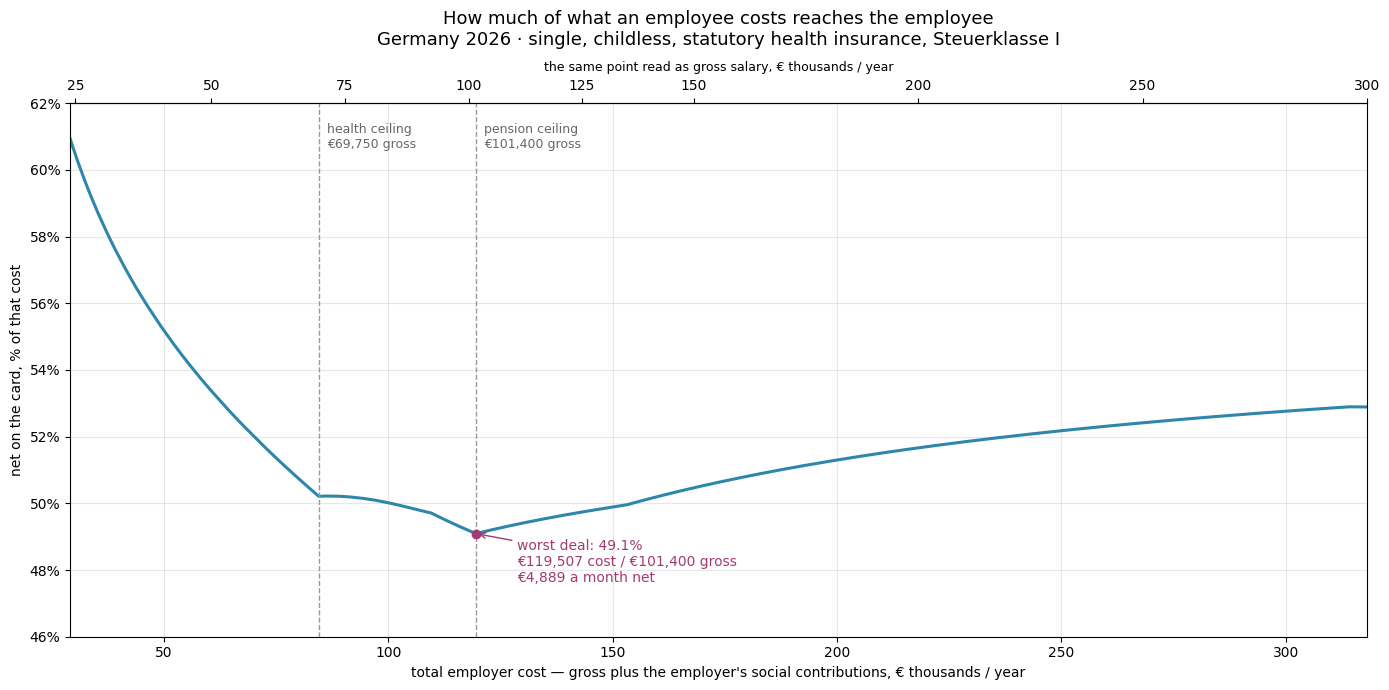

In [3]:
HEALTH_CEILING = year(SYSTEM.bbg_health).employer_cost
PENSION_CEILING = year(SYSTEM.bbg_pension).employer_cost
worst = curve.loc[curve["take_home_share"].idxmin()]

fig, ax = plt.subplots(figsize=(14, 7))
ax.plot(
    curve["employer_cost"] / 1000, curve["take_home_share"] * 100, color="#2E86AB", lw=2.2
)

for cost, label in (
    (HEALTH_CEILING, f"health ceiling\n€{SYSTEM.bbg_health:,.0f} gross"),
    (PENSION_CEILING, f"pension ceiling\n€{SYSTEM.bbg_pension:,.0f} gross"),
):
    ax.axvline(cost / 1000, color="#999999", ls="--", lw=1)
    ax.annotate(
        label,
        xy=(cost / 1000, 61.4),
        xytext=(6, 0),
        textcoords="offset points",
        fontsize=9,
        color="#666666",
        va="top",
    )

ax.plot(worst["employer_cost"] / 1000, worst["take_home_share"] * 100, "o", color="#A23B72")
ax.annotate(
    f"worst deal: {worst['take_home_share'] * 100:.1f}%\n"
    f"€{worst['employer_cost']:,.0f} cost / €{worst['yearly_gross']:,.0f} gross\n"
    f"€{worst['net'] / 12:,.0f} a month net",
    xy=(worst["employer_cost"] / 1000, worst["take_home_share"] * 100),
    xytext=(30, -35),
    textcoords="offset points",
    fontsize=10,
    color="#A23B72",
    arrowprops=dict(arrowstyle="->", color="#A23B72", lw=1),
)

ax.set_title(
    "How much of what an employee costs reaches the employee\n"
    "Germany 2026 · single, childless, statutory health insurance, Steuerklasse I",
    fontsize=13,
    pad=42,
)
ax.set_xlabel("total employer cost — gross plus the employer's social contributions, € thousands / year")
ax.set_ylabel("net on the card, % of that cost")
ax.set_ylim(46, 62)
# Exactly the data range: the top axis interpolates, and outside the range an
# interpolation clamps and would mislabel its ticks.
ax.set_xlim(curve["employer_cost"].iloc[0] / 1000, curve["employer_cost"].iloc[-1] / 1000)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.grid(True, alpha=0.3)

to_gross = lambda cost: np.interp(cost, curve["employer_cost"] / 1000, curve["yearly_gross"] / 1000)
to_cost = lambda gross: np.interp(gross, curve["yearly_gross"] / 1000, curve["employer_cost"] / 1000)
top = ax.secondary_xaxis("top", functions=(to_gross, to_cost))
top.set_xticks([25, 50, 75, 100, 125, 150, 200, 250, 300])
top.set_xlabel("the same point read as gross salary, € thousands / year", fontsize=9, labelpad=6)

plt.tight_layout()
plt.show()

## Round Numbers

In [4]:
ROUND_SALARIES = [
    30_000, 40_000, 50_000, 60_000, 70_000, 80_000,
    100_000, 120_000, 150_000, 200_000, 300_000,
]

table = pd.DataFrame(
    [
        {
            "gross / yr": f"€{y.yearly_gross:,.0f}",
            "employer cost / yr": f"€{y.employer_cost:,.0f}",
            "net / yr": f"€{y.net:,.0f}",
            "net / month": f"€{y.net / 12:,.0f}",
            "% of employer cost": f"{y.take_home_share * 100:.1f}%",
            "% of gross": f"{y.net / y.yearly_gross * 100:.1f}%",
        }
        for y in (year(g) for g in ROUND_SALARIES)
    ]
)
table

,gross / yr,employer cost / yr,net / yr,net / month,% of employer cost,% of gross
0,"€30,000","€36,345","€21,223","€1,769",58.4%,70.7%
1,"€40,000","€48,460","€26,887","€2,241",55.5%,67.2%
2,"€50,000","€60,575","€32,329","€2,694",53.4%,64.7%
3,"€60,000","€72,690","€37,551","€3,129",51.7%,62.6%
4,"€70,000","€84,779","€42,570","€3,547",50.2%,60.8%
5,"€80,000","€95,839","€48,035","€4,003",50.1%,60.0%
6,"€100,000","€117,959","€58,014","€4,835",49.2%,58.0%
7,"€120,000","€138,107","€68,528","€5,711",49.6%,57.1%
8,"€150,000","€168,107","€84,836","€7,070",50.5%,56.6%
9,"€200,000","€218,107","€112,681","€9,390",51.7%,56.3%


In [5]:
best = curve.loc[curve["take_home_share"].idxmax()]
top_end = curve.iloc[-1]

print(f"Best in range:   {best['take_home_share'] * 100:>5.1f}%  "
      f"at €{best['yearly_gross']:>9,.0f} gross  (€{best['employer_cost']:,.0f} cost)")
print(f"Worst in range:  {worst['take_home_share'] * 100:>5.1f}%  "
      f"at €{worst['yearly_gross']:>9,.0f} gross  (€{worst['employer_cost']:,.0f} cost)")
print(f"At the top end:  {top_end['take_home_share'] * 100:>5.1f}%  "
      f"at €{top_end['yearly_gross']:>9,.0f} gross  (€{top_end['employer_cost']:,.0f} cost)")
print()
print(f"The dip is worth {(best['take_home_share'] - worst['take_home_share']) * 100:.1f} "
      f"percentage points of everything the employer spends.")

Best in range:    60.9%  at €   24,000 gross  (€29,076 cost)
Worst in range:   49.1%  at €  101,400 gross  (€119,507 cost)
At the top end:   52.9%  at €  300,000 gross  (€318,107 cost)

The dip is worth 11.8 percentage points of everything the employer spends.


## Where the Rest Goes

The left panel is the same curve split into its four parts, which always add up
to the whole employer cost: net, income tax with Soli, the employee's half of
the social insurance and the employer's half. The two insurance bands stop
growing at the ceilings, which is exactly why the green band widens again on
the right.

The right panel is the marginal version of the first chart — of the *next* euro
an employer spends, how much reaches the card. It is the number a raise negotiation
actually turns on, and its plateaus are real rather than an artefact of the
measuring step: in the band just below the health ceiling barely 40 cents of
each extra euro survive; crossing that ceiling frees 11.15 employee cents and
10.55 employer cents at once and the marginal jumps to 51; it sags again to 46
as the tariff reaches its 42% zone, and to 42 where the Solidaritätszuschlag
phases in at 11.9% of the excess; crossing the pension ceiling frees the last
10.6 cents on each side, and from there only the tariff still bites — 53 while
the Soli phase-in lasts, 56 after it, and 52.5 once the 45% rate takes over.

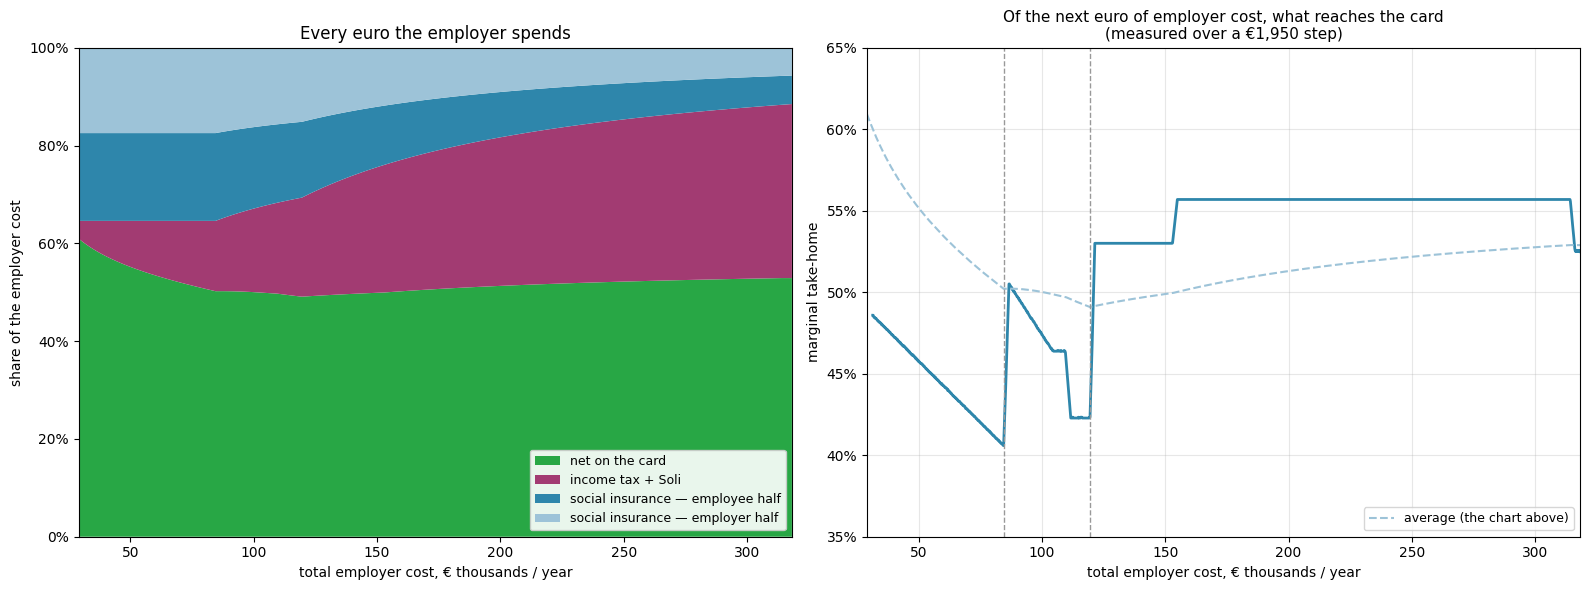

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

x = curve["employer_cost"] / 1000
for panel in axes:
    panel.set_xlim(x.iloc[0], x.iloc[-1])

share = lambda column: curve[column] / curve["employer_cost"] * 100
axes[0].stackplot(
    x,
    share("net"),
    share("tax"),
    share("employee_social"),
    share("employer_social"),
    labels=[
        "net on the card",
        "income tax + Soli",
        "social insurance — employee half",
        "social insurance — employer half",
    ],
    colors=["#28A745", "#A23B72", "#2E86AB", "#9DC3D8"],
)
axes[0].set_title("Every euro the employer spends")
axes[0].set_xlabel("total employer cost, € thousands / year")
axes[0].set_ylabel("share of the employer cost")
axes[0].set_ylim(0, 100)
axes[0].yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
axes[0].legend(loc="lower right", fontsize=9, framealpha=0.9)

window = round(2_000 / GROSS_STEP)
marginal = curve["net"].diff(window) / curve["employer_cost"].diff(window)
axes[1].plot(x, marginal * 100, color="#2E86AB", lw=2)
axes[1].plot(x, curve["take_home_share"] * 100, color="#9DC3D8", lw=1.5, ls="--",
             label="average (the chart above)")
for cost in (HEALTH_CEILING, PENSION_CEILING):
    axes[1].axvline(cost / 1000, color="#999999", ls="--", lw=1)
axes[1].set_title(
    f"Of the next euro of employer cost, what reaches the card\n"
    f"(measured over a €{window * GROSS_STEP:,} step)",
    fontsize=11,
)
axes[1].set_xlabel("total employer cost, € thousands / year")
axes[1].set_ylabel("marginal take-home")
axes[1].set_ylim(35, 65)
axes[1].yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
axes[1].legend(loc="lower right", fontsize=9)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()